# Sprint 2 · Semana 6: baseline, variantes de los datos y diagnósticos del modelo

Tesis: Detección Automatizada y Priorización de Eventos Adversos en Notas Clínicas mediante un Flujo de Procesamiento (Pipeline) de NLP y
Aprendizaje Automático — Aplicación de la Matriz de Priorización del Modelo GEMSES sobre MIMIC-IV

Autor: Carlos Pérez Pérez · Curso: MIA-14 Trabajo de Investigación II · Docente: Dr. Glen Rodríguez · 23 de octubre de 2026

El presente cuaderno reúne el experimento de la semana 6, el cual cierra el Sprint 2 con el *baseline*, dos variantes de los datos y los
diagnósticos del modelo. El cuaderno no vuelve a entrenar el modelo, dado que la corrida completa tarda cerca de tres horas, sino que lee los
resultados que deja el script `src/experimentos_datos.py` en la carpeta `reportes/` y a partir de ellos construye cada tabla y cada figura. De
esta manera, cada cifra del texto puede verificarse en las celdas de código, y no se requiere acceso a los datos de MIMIC-IV, protegidos por el
acuerdo de uso de PhysioNet.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
leer = lambda n: json.loads((RAIZ / "reportes" / n).read_text(encoding="utf-8"))
E, F, D = leer("eda_resumen.json"), leer("fe_resultados.json"), leer("datos_resultados.json")
folds = pd.read_csv(RAIZ / "reportes" / "datos_folds.csv")
mil = lambda x: f"{round(x):,}".replace(",", " ")
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
AZUL, ROJO, GRIS, CLARO, VERDE = "#1F4E79", "#9B2226", "#8A8A8A", "#9FB8CF", "#4F7942"
print("Resultados leídos:", D["generado"], "· semilla", D["semilla"], "· variante elegida por validación cruzada:", D["elegida_por_cv"])

Resultados leídos: 2026-10-22T17:32:15 · semilla 42 · variante elegida por validación cruzada: D2


## 1. Punto de partida: lo que mostró el EDA

Como se aprecia en la Figura 1, la proporción real de hospitalizaciones con evento adverso entre las que tienen epicrisis en MIMIC-IV es
27.6%, mientras que el corpus de estudio tiene 53.8% porque se construyó balanceado a propósito.
Por consiguiente, el valor predictivo positivo se calcula con la prevalencia real y no con la proporción del corpus. Asimismo, casi la mitad de
las epicrisis con evento corresponde a complicaciones de procedimientos y de la atención, y la etiqueta presenta ruido en las positivas que lo
son solo por un código de caída. De estas 6 296 positivas, apenas 159 registran el
hospital como lugar de ocurrencia. Al respecto, 4 286 pertenecen a la época CIE-9, la cual no tiene un código de lugar para el
hospital, y en la época CIE-10, donde sí existe, solo 159 de 2 010 lo registran
(7.9%). Este hallazgo dio origen a las variantes de los datos que se describen en la sección 3, en las cuales
se excluyen del entrenamiento las positivas y las negativas dudosas.

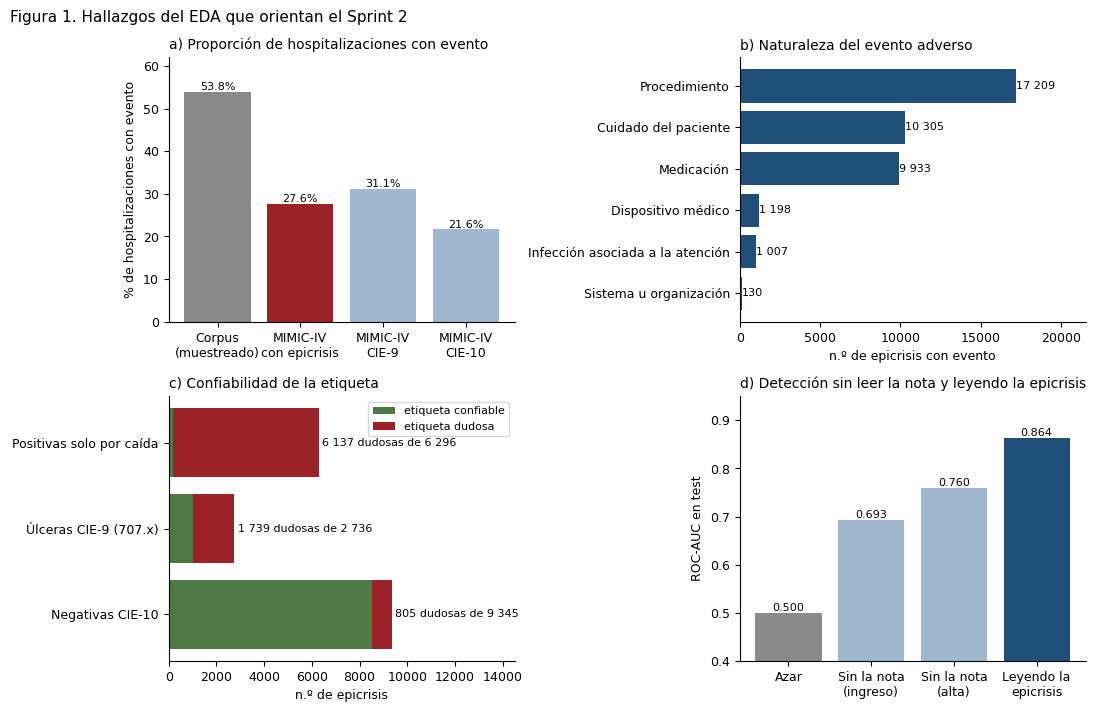

Positivas solo por caída: 6296 · con el hospital como lugar: 159 · CIE-9: 4286 · CIE-10: 2010 (en el hospital: 159 )


In [2]:
pr, n, r, ctx = E["prevalencia_real"], E["naturaleza"]["conteo"], E["ruido_etiqueta"], E["variables"]["contexto"]
fig, ax = plt.subplots(2, 2, figsize=(11, 7.2))
b = ax[0, 0].bar(["Corpus\n(muestreado)", "MIMIC-IV\ncon epicrisis", "MIMIC-IV\nCIE-9", "MIMIC-IV\nCIE-10"],
                 [E["balance"]["All"]["pct_positivas"], pr["todas"]["pct_positivas_con_epicrisis"],
                  pr["por_epoca"]["CIE-9"]["pct_positivas_con_epicrisis"], pr["por_epoca"]["CIE-10"]["pct_positivas_con_epicrisis"]],
                 color=[GRIS, ROJO, CLARO, CLARO])
ax[0, 0].bar_label(b, fmt="%.1f%%", fontsize=8); ax[0, 0].set(ylabel="% de hospitalizaciones con evento", ylim=(0, 62))
ax[0, 0].set_title("a) Proporción de hospitalizaciones con evento", loc="left", fontsize=10)
NOM = {"Medicacion": "Medicación", "Dispositivo medico": "Dispositivo médico", "Infeccion nosocomial": "Infección asociada a la atención",
       "Sistema/Organizacion": "Sistema u organización"}
k = sorted(n, key=n.get)
b = ax[0, 1].barh([NOM.get(i, i) for i in k], [n[i] for i in k], color=AZUL)
ax[0, 1].bar_label(b, labels=[mil(n[i]) for i in k], fontsize=8)
ax[0, 1].set(xlabel="n.º de epicrisis con evento", xlim=(0, max(n.values()) * 1.25)); ax[0, 1].xaxis.set_major_locator(plt.MaxNLocator(5))
ax[0, 1].set_title("b) Naturaleza del evento adverso", loc="left", fontsize=10)
filas = [("Negativas CIE-10", r["negativas"]["cie10"]["n"] - r["negativas"]["cie10"]["con_alguno"], r["negativas"]["cie10"]["con_alguno"]),
         ("Úlceras CIE-9 (707.x)", r["ulcera_cie9"]["positivas_de_la_familia"] - r["ulcera_cie9"]["sin_codigo_707_0"], r["ulcera_cie9"]["sin_codigo_707_0"]),
         ("Positivas solo por caída", r["caidas"]["con_el_hospital_como_lugar"], r["caidas"]["sin_el_hospital_como_lugar"])]
y = np.arange(3)
ax[1, 0].barh(y, [f[1] for f in filas], color=VERDE, label="etiqueta confiable")
ax[1, 0].barh(y, [f[2] for f in filas], left=[f[1] for f in filas], color=ROJO, label="etiqueta dudosa")
for i, f in enumerate(filas):
    ax[1, 0].text(f[1] + f[2] + 150, i, f"{mil(f[2])} dudosas de {mil(f[1] + f[2])}", va="center", fontsize=8)
ax[1, 0].set_yticks(y, [f[0] for f in filas]); ax[1, 0].legend(fontsize=8, loc="upper right")
ax[1, 0].set(xlabel="n.º de epicrisis", xlim=(0, 14500))
ax[1, 0].set_title("c) Confiabilidad de la etiqueta", loc="left", fontsize=10)
b = ax[1, 1].bar(["Azar", "Sin la nota\n(ingreso)", "Sin la nota\n(alta)", "Leyendo la\nepicrisis"],
                 [ctx["dummy"]["roc_auc"], ctx["al_ingreso"]["roc_auc"], ctx["al_alta"]["roc_auc"], ctx["modelo_de_texto"]["roc_auc"]],
                 color=[GRIS, CLARO, CLARO, AZUL])
ax[1, 1].bar_label(b, fmt="%.3f", fontsize=8); ax[1, 1].set(ylabel="ROC-AUC en test", ylim=(0.4, 0.95))
ax[1, 1].set_title("d) Detección sin leer la nota y leyendo la epicrisis", loc="left", fontsize=10)
fig.suptitle("Figura 1. Hallazgos del EDA que orientan el Sprint 2", fontsize=11, x=0.01, ha="left")
fig.tight_layout(); plt.show()
k = r["caidas"]
print("Positivas solo por caída:", k["positivas_solo_por_caida"], "· con el hospital como lugar:", k["con_el_hospital_como_lugar"],
      "· CIE-9:", k["cie9"]["n"], "· CIE-10:", k["cie10"]["n"], "(en el hospital:", k["cie10"]["en_hospital"], ")")

Fuente: elaboración propia a partir de `reportes/eda_resumen.json`.

En el panel d) de la Figura 1 se observa que un modelo que no lee la nota ya alcanza un ROC-AUC de
0.693 con los datos del ingreso y de 0.760 con
los del alta, frente a 0.864 del modelo que lee la epicrisis. En consecuencia, es preciso
tomar en consideración que el tipo de paciente anticipa una parte de la etiqueta, aspecto que se revisará con la evaluación por subgrupo del
Sprint 3.

## 2. Punto de partida: el feature engineering de la semana 5

Como se aprecia en el Cuadro 2 y en la Tabla 1, la ablación de la semana 5 agregó un bloque de atributos a la vez sobre la misma regresión
logística. La métrica central es la PR-AUC (área bajo la curva de precisión y sensibilidad), la cual resume para todos los umbrales la capacidad
del modelo para encontrar los eventos sin acumular falsas alarmas. Se observó que la PR-AUC pasó de 0.8667 con las
palabras de la nota (A) a 0.8732 con todos los bloques (A+B+C), configuración que fue mejor que A en los 5
*folds* y que se adoptó como modelo de esta semana. Cada *fold* es una de las 5 partes en que se divide el conjunto de *train*, de modo que el
modelo se entrena con cuatro y se evalúa con la que queda, cinco veces.

Cuadro 1. Bloques de atributos comparados en la semana 5

| Bloque | Descripción | Aporte al modelo | Ejemplo |
|---|---|---|---|
| A | Palabras sueltas de la epicrisis (TF-IDF, hasta 20 000 términos) | Qué palabras usa la nota y cuánto pesan | *fall* (caída), *wound* (herida), *vancomycin* |
| B | Pares de palabras consecutivas (bigramas, hasta 20 000 términos) | Expresiones de dos palabras que una palabra sola no capta | *pressure ulcer* (úlcera por presión) |
| C | 18 variables de la hospitalización y el largo de la nota | Datos del paciente y de la atención, sin leer el texto | edad, servicio, días de estancia, paso por UCI, traslados, número de medicamentos y de cultivos |

Con estos bloques se armaron cuatro configuraciones, agregando un bloque a la vez con el fin de medir el aporte de cada uno, tal como se aprecia
en el Cuadro 2.

Cuadro 2. Configuraciones de la ablación (validación cruzada, 5 *folds*)

| Configuración | Bloques | PR-AUC (validación cruzada) | Diferencia con A |
|---|---|---|---|
| A | palabras (*baseline*) | 0.8667 | referencia |
| A+B | palabras y pares de palabras | 0.8688 | +0.0021 |
| A+C | palabras, variables de la hospitalización y largo de la nota | 0.8714 | +0.0047 |
| A+B+C | todos los bloques (configuración adoptada) | 0.8732 | +0.0065 |

Fuente: elaboración propia a partir de `reportes/fe_resultados.json`.

Como se aprecia en el Cuadro 2, el bloque C aporta más que el bloque B, y la combinación de ambos alcanza la mayor PR-AUC; por ello, A+B+C se
mantuvo fijo en el experimento de las variantes de los datos (D0, D1 y D2). La Tabla 1, en la celda siguiente, presenta las mismas cifras
calculadas a partir de los resultados, junto con su desviación estándar.

In [3]:
t1 = pd.DataFrame({k: {"PR-AUC (media)": v["pr_auc"]["media"], "desviación estándar": v["pr_auc"]["std"],
                       "diferencia con A": v["pr_auc"]["media"] - F["cv"]["A"]["pr_auc"]["media"]} for k, v in F["cv"].items()}).T.round(4)
t1.index.name = "Tabla 1. Configuración (validación cruzada, 5 folds)"
t1

,PR-AUC (media),desviación estándar,diferencia con A
"Tabla 1. Configuración (validación cruzada, 5 folds)",,,
A,0.8667,0.0035,0.0000
A+B,0.8688,0.0034,0.0021
A+C,0.8714,0.0021,0.0047
A+B+C,0.8732,0.0025,0.0065


Fuente: elaboración propia a partir de `reportes/fe_resultados.json`.

## 3. Diseño del experimento: baseline y variantes de los datos

Siguiendo la indicación de centrar la semana en los datos, se mantuvo fijo el modelo A+B+C y se cambió únicamente el conjunto con el cual se
entrena. D0 corresponde a los datos actuales y constituye el *baseline*, mientras que D1 excluye del entrenamiento las negativas que tienen un
código de evento fuera de la tabla de la etiqueta. Por su parte, D2 excluye además las positivas cuya única evidencia es una caída sin el
hospital como lugar de ocurrencia (en CIE-9, todas las caídas) o una úlcera CIE-9 que no es por presión. Las tres variantes se evaluaron sobre
las mismas epicrisis, es decir, las de validación y de *test* que ninguna variante excluye, con la etiqueta original. Asimismo, se mantuvo el
protocolo de la semana 5, con validación cruzada de 5 *folds* por paciente y semilla 42. Como se aprecia en la Tabla 2, D1 excluye
617 epicrisis del entrenamiento y D2 excluye 6 917,
mientras que la evaluación común reúne 48 998 epicrisis en *train* y
12 321 en *test* para las tres variantes.

In [4]:
m = D["marcas"]
t2 = pd.DataFrame({
    "excluidas del entrenamiento (train)": [0, m["train"]["negativas_dudosas"], m["train"]["negativas_dudosas"] + m["train"]["positivas_dudosas"]],
    "filas de entrenamiento (train completo)": [D["filas_de_entrenamiento_train_completo"][v] for v in ("D0", "D1", "D2")],
}, index=[f"{v}: {D['variantes'][v]}" for v in ("D0", "D1", "D2")])
t2.index.name = "Tabla 2. Variante"
print("Epicrisis de evaluación común: train", m["train"]["filas_de_evaluacion_comun"], "· test", m["test"]["filas_de_evaluacion_comun"])
t2

Epicrisis de evaluación común: train 48998 · test 12321


,excluidas del entrenamiento (train),filas de entrenamiento (train completo)
Tabla 2. Variante,,
D0: datos actuales,0,55915
D1: sin negativas dudosas,617,55298
D2: sin negativas ni positivas dudosas,6917,48998


Fuente: elaboración propia a partir de `reportes/datos_resultados.json`.

## 4. Resultados por fold

Como se aprecia en la Tabla 3 y en la Figura 2, D2 obtuvo la mayor PR-AUC en los 5 *folds*, con diferencias frente a D0 que van de +0.0079
a +0.0136, mientras que D1 apenas se separa de D0 (+0.0009 en promedio). De esta manera, en las
epicrisis sin etiqueta dudosa, la mejora proviene de excluir las positivas dudosas y no de excluir las negativas.

variante,D0,D1,D2,D1 − D0,D2 − D0
Tabla 3. PR-AUC por fold (mismas epicrisis),,,,,
1,0.8459,0.8474,0.8567,0.0014,0.0108
2,0.8448,0.8455,0.8527,0.0007,0.0079
3,0.8385,0.8396,0.8467,0.0011,0.0082
4,0.8432,0.8436,0.8542,0.0003,0.0110
5,0.8431,0.8439,0.8566,0.0008,0.0136
media,0.8431,0.8440,0.8534,0.0009,0.0103
desviación estándar,0.0028,0.0029,0.0041,0.0004,0.0023


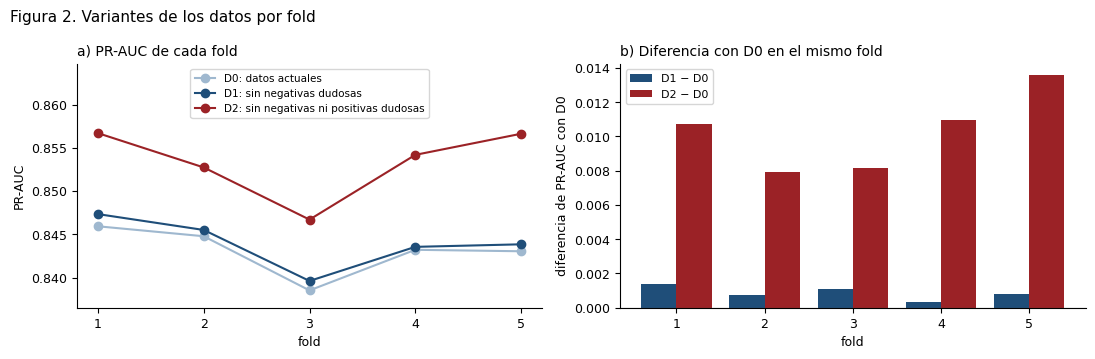

In [5]:
p = folds.pivot(index="fold", columns="variante", values="pr_auc_comun")
t3 = p.copy()
t3["D1 − D0"], t3["D2 − D0"] = p["D1"] - p["D0"], p["D2"] - p["D0"]
t3.loc["media"] = t3.iloc[:5].mean(); t3.loc["desviación estándar"] = t3.iloc[:5].std()
t3.index.name = "Tabla 3. PR-AUC por fold (mismas epicrisis)"
display(t3.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for v, col in (("D0", CLARO), ("D1", AZUL), ("D2", ROJO)):
    ax[0].plot(p.index, p[v], "o-", color=col, label=f"{v}: {D['variantes'][v]}")
ax[0].set(xlabel="fold", ylabel="PR-AUC", xticks=list(p.index), ylim=(p.min().min() - 0.002, p.max().max() + 0.008))
ax[0].legend(fontsize=7.5, loc="upper center")
ax[0].set_title("a) PR-AUC de cada fold", loc="left", fontsize=10)
x = np.arange(5)
ax[1].bar(x - 0.2, t3["D1 − D0"].iloc[:5], 0.4, color=AZUL, label="D1 − D0")
ax[1].bar(x + 0.2, t3["D2 − D0"].iloc[:5], 0.4, color=ROJO, label="D2 − D0")
ax[1].axhline(0, c="gray", lw=0.8); ax[1].set_xticks(x, p.index); ax[1].legend(fontsize=8)
ax[1].set(xlabel="fold", ylabel="diferencia de PR-AUC con D0"); ax[1].set_title("b) Diferencia con D0 en el mismo fold", loc="left", fontsize=10)
fig.suptitle("Figura 2. Variantes de los datos por fold", fontsize=11, x=0.01, ha="left"); fig.tight_layout(); plt.show()

Fuente: elaboración propia a partir de `reportes/datos_folds.csv`.

Con el criterio de adopción de la semana 6, es decir, la mejora consistente de la métrica central, se eligió D2, cuya PR-AUC media subió de
0.8431 a 0.8534 en las epicrisis sin etiqueta dudosa. La desviación
estándar también subió, de 0.0028 a 0.0041; sin embargo, la mejora más
pequeña (+0.0079) es casi el triple de la variación de D0 entre *folds*, y D2 entrena con
12% menos filas.

## 5. Resultados en test y con todas las epicrisis

La Tabla 4 presenta la medición única en *test*, en la cual la PR-AUC de las epicrisis sin etiqueta dudosa fue 0.8562
con D0 y 0.8671 con D2. No obstante, los intervalos de confianza al 95% se solapan, por lo cual la decisión se apoya
en la comparación por *fold*. Asimismo, con todas las epicrisis y la etiqueta original, D2 queda por debajo de D0 en los 5 *folds*
(0.8477 frente a 0.8732 en validación cruzada) y también en
*test* (0.8580 frente a 0.8830). A criterio del autor, el modelo entrenado sin esas
caídas y úlceras deja de marcarlas como evento, mientras que la etiqueta original sí las cuenta. Por consiguiente, elegir D2 supone aceptar que
esas positivas no son eventos de la atención, criterio que proviene del EDA y que el experimento no demuestra por sí mismo. Adicionalmente, D2
excluye del entrenamiento casi todas las positivas que lo son solo por una caída (en todo el corpus quedan 159 de
6 296), de modo que con estos datos no es posible medir si el modelo reconoce las caídas intrahospitalarias.

In [6]:
t4 = pd.DataFrame({f"{v} · {ev}": {"PR-AUC": te["pr_auc"], "IC 95% (pacientes)": f"{te['pr_auc_ic95_pacientes'][0]:.4f}–{te['pr_auc_ic95_pacientes'][1]:.4f}",
                                       "ROC-AUC": te["roc_auc"], "sensibilidad": te["recall"], "especificidad": te["especificidad"]}
                   for v in ("D0", "D1", "D2") for ev, te in (("sin etiqueta dudosa", D["test"][v]["comun"]), ("todas, etiqueta original", D["test"][v]["completa"]))}).T
t4.index.name = "Tabla 4. Test (medición única)"
t4.style.format(lambda x: f"{x:.4f}" if isinstance(x, float) else x)

,PR-AUC,IC 95% (pacientes),ROC-AUC,sensibilidad,especificidad
Tabla 4. Test (medición única),,,,,
D0 · sin etiqueta dudosa,0.8562,0.8475–0.8651,0.8603,0.7469,0.8014
"D0 · todas, etiqueta original",0.8830,0.8754–0.8905,0.8681,0.7754,0.7924
D1 · sin etiqueta dudosa,0.8575,0.8487–0.8662,0.8610,0.7509,0.8013
"D1 · todas, etiqueta original",0.8828,0.8751–0.8902,0.8680,0.7803,0.7911
D2 · sin etiqueta dudosa,0.8671,0.8589–0.8749,0.8706,0.7689,0.8038
"D2 · todas, etiqueta original",0.8580,0.8493–0.8664,0.8398,0.7189,0.7950


In [7]:
cv = D["cv"]; pc = folds.pivot(index="fold", columns="variante", values="pr_auc_completa")
print("Todas las epicrisis, etiqueta original (validación cruzada): D0", cv["D0"]["completa"]["pr_auc"]["media"],
      "· D2", cv["D2"]["completa"]["pr_auc"]["media"], "· folds con D2 por debajo de D0:", int((pc["D2"] < pc["D0"]).sum()))

Todas las epicrisis, etiqueta original (validación cruzada): D0 0.8732 · D2 0.8477 · folds con D2 por debajo de D0: 5


Fuente: elaboración propia a partir de `reportes/datos_resultados.json` y `reportes/datos_folds.csv`.

## 6. Traducción de la PR-AUC a eventos adversos

Una diferencia de milésimas en la PR-AUC no indica cuántos eventos adicionales se detectan, por lo cual se aplicaron la sensibilidad y la
especificidad medidas en *test* con el umbral de 0.5 a 10 000 hospitalizaciones con epicrisis. Con la prevalencia real (27.6%), estas
corresponden a 2 759 hospitalizaciones con evento según los códigos. Se supone, además, que estas tasas valen para la base,
aunque el corpus tiene más epicrisis de la época CIE-9 (71.1%) que la base
(63.1%). Como se aprecia en
la Tabla 5, el *feature engineering* suma 11 eventos detectados y 8 falsas alarmas,
mientras que la limpieza de los datos, en las epicrisis sin etiqueta dudosa, suma 60 eventos y reduce
17 falsas alarmas. Sin embargo, es preciso tomar en consideración que este cálculo supone que todos los eventos son
como los de las epicrisis comparadas. De hecho, con todas las epicrisis y la etiqueta original, D2 detecta 156 eventos
codificados menos que D0, por lo cual la mejora no se extrapola a toda la base de MIMIC-IV.

In [8]:
prev = E["balance"]["prevalencia_real_con_epicrisis"]
eventos, sin_evento = 10_000 * prev, 10_000 * (1 - prev)

def por_10000(t):
    detectados = t["recall"] * eventos                    # verdaderos positivos
    falsas = (1 - t["especificidad"]) * sin_evento        # falsos positivos
    return {"detectados (VP)": round(detectados), "se escapan (FN)": round(eventos) - round(detectados),
            "falsas alarmas (FP)": round(falsas), "VPP: de cada 100 alertas, con evento": round(100 * detectados / (detectados + falsas))}

t5 = pd.DataFrame({
    "A, baseline de la semana 3 · todas": por_10000(F["test"]["A"]),
    "A+B+C (= D0) · todas": por_10000(F["test"]["A+B+C"]),
    "D0 · sin etiqueta dudosa": por_10000(D["test"]["D0"]["comun"]),
    "D2 · sin etiqueta dudosa": por_10000(D["test"]["D2"]["comun"]),
    "D2 · todas, etiqueta original": por_10000(D["test"]["D2"]["completa"]),
}).T
t5.index.name = f"Tabla 5. Por cada 10 000 hospitalizaciones ({mil(eventos)} con evento)"
t5

,detectados (VP),se escapan (FN),falsas alarmas (FP),"VPP: de cada 100 alertas, con evento"
Tabla 5. Por cada 10 000 hospitalizaciones (2 759 con evento),,,,
"A, baseline de la semana 3 · todas",2128,631,1495,59
A+B+C (= D0) · todas,2139,620,1503,59
D0 · sin etiqueta dudosa,2061,698,1438,59
D2 · sin etiqueta dudosa,2121,638,1421,60
"D2 · todas, etiqueta original",1983,776,1484,57


Fuente: elaboración propia a partir de `reportes/fe_resultados.json`, `reportes/datos_resultados.json` y `reportes/eda_resumen.json`.

## 7. Diagnósticos del modelo

La Tabla 6 presenta la importancia por permutación con D2, medida como la caída de la PR-AUC de validación al barajar cada grupo de atributos.
Se observa que las palabras del texto son, con diferencia, lo que más aporta (0.1259), seguidas de los bigramas
(0.0333), la estancia (0.0136) y el servicio (0.0061), y que
los tres primeros grupos mantienen el mismo orden en los 5 *folds*. Como se aprecia en la Figura 3, la curva de aprendizaje del *fold* 1 muestra
una brecha de 0.078 entre *train* y validación, la cual a criterio del autor es moderada, y
una validación que todavía sube en el último tramo (+0.0039). Asimismo, la curva de
calibración se mantiene cerca de la diagonal en el corpus (Brier de 0.1533 con D2), aunque para usar la
probabilidad como riesgo con la prevalencia real se requiere recalibrarla.

,caída de la PR-AUC (media),desviación,folds en el top 5
Tabla 6. Grupo de atributos (D2),,,
palabras del texto,0.1259,0.0028,5
bigramas del texto,0.0333,0.0014,5
estancia (días),0.0136,0.0019,5
servicio al ingreso,0.0061,0.0009,5
largo de la nota,0.0053,0.0007,4
servicio al alta,0.0044,0.0007,0
destino al alta,0.0038,0.0010,1
n.º de cultivos,0.0037,0.0003,0


Top 5 por fold: [['texto: palabras', 'texto: bigramas', 'estancia_dias', 'servicio', 'largo de la nota'], ['texto: palabras', 'texto: bigramas', 'estancia_dias', 'servicio', 'largo de la nota'], ['texto: palabras', 'texto: bigramas', 'estancia_dias', 'largo de la nota', 'servicio'], ['texto: palabras', 'texto: bigramas', 'estancia_dias', 'servicio', 'largo de la nota'], ['texto: palabras', 'texto: bigramas', 'estancia_dias', 'servicio', 'destino_alta']]
Brecha final: 0.0784 · último tramo: 0.0039 · Brier D2: 0.1533


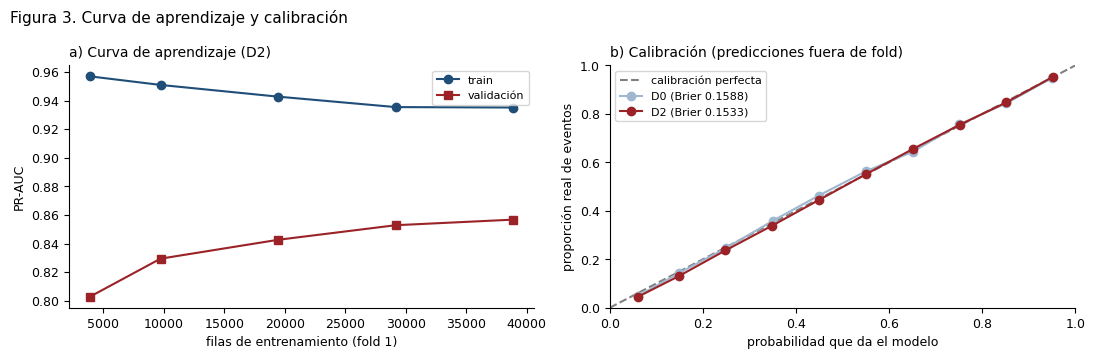

In [9]:
imp, veces = D["importancia"][D["elegida_por_cv"]], D["importancia_veces_en_top5"]
t6 = pd.DataFrame({k: {"caída de la PR-AUC (media)": v["media"], "desviación": v["std"], "folds en el top 5": veces.get(k, 0)}
                   for k, v in imp.items()}).T.sort_values("caída de la PR-AUC (media)", ascending=False).head(8).round(4)
t6 = t6.astype({"folds en el top 5": int}).rename(index={"texto: palabras": "palabras del texto", "texto: bigramas": "bigramas del texto",
     "estancia_dias": "estancia (días)", "servicio": "servicio al ingreso", "servicio_alta": "servicio al alta",
     "destino_alta": "destino al alta", "n_cultivos": "n.º de cultivos", "n_medicamentos": "n.º de medicamentos"})
t6.index.name = "Tabla 6. Grupo de atributos (D2)"
display(t6)
print("Top 5 por fold:", D["importancia_top5_por_fold"])
c = pd.DataFrame(D["curva_de_aprendizaje"]["puntos"])
print("Brecha final:", round(c.pr_auc_train.iloc[-1] - c.pr_auc_validacion.iloc[-1], 4), "· último tramo:",
      round(c.pr_auc_validacion.iloc[-1] - c.pr_auc_validacion.iloc[-2], 4), "· Brier D2:", D["calibracion"]["D2"]["brier"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(c.filas, c.pr_auc_train, "o-", color=AZUL, label="train"); ax[0].plot(c.filas, c.pr_auc_validacion, "s-", color=ROJO, label="validación")
ax[0].set(xlabel="filas de entrenamiento (fold 1)", ylabel="PR-AUC"); ax[0].legend(fontsize=8)
ax[0].set_title("a) Curva de aprendizaje (D2)", loc="left", fontsize=10)
ax[1].plot([0, 1], [0, 1], ls="--", c="gray", label="calibración perfecta")
for v, col in (("D0", CLARO), ("D2", ROJO)):
    k = D["calibracion"][v]
    ax[1].plot(k["prob_media"], k["frecuencia_real"], "o-", color=col, label=f"{v} (Brier {k['brier']:.4f})")
ax[1].set(xlabel="probabilidad que da el modelo", ylabel="proporción real de eventos", xlim=(0, 1), ylim=(0, 1)); ax[1].legend(fontsize=8)
ax[1].set_title("b) Calibración (predicciones fuera de fold)", loc="left", fontsize=10)
fig.suptitle("Figura 3. Curva de aprendizaje y calibración", fontsize=11, x=0.01, ha="left"); fig.tight_layout(); plt.show()

Fuente: elaboración propia a partir de `reportes/datos_resultados.json`.

Respecto de la colinealidad y la coherencia de los datos, la celda siguiente muestra el factor de inflación de la varianza (VIF) de las
variables numéricas de la hospitalización, el cual no supera 5 en ninguna de ellas (máximo de 3.05). Asimismo, muestra la
única categoría que aparece en *test* sin estar en *train* (DENT, en el servicio al alta), la cual el modelo trata como infrecuente.

In [10]:
print("VIF:", {k: v for k, v in sorted(D["vif"].items(), key=lambda kv: -kv[1])})
print("Categorías solo en test:", {k: v for k, v in D["coherencia"]["categorias_solo_en_test"].items() if v})

VIF: {'n_unidades': 3.05, 'n_traslados': 2.89, 'n_medicamentos': 2.26, 'estancia_dias': 2.2, 'dias_uci': 1.83, 'n_cultivos': 1.81, 'n_servicios': 1.15, 'edad': 1.1, 'horas_emergencia': 1.05}
Categorías solo en test: {'servicio_alta': ['DENT']}


## 8. Decisión y siguiente sprint

Una vez analizados los resultados, se concluye que, en las epicrisis sin etiqueta dudosa, excluir del entrenamiento las positivas dudosas mejora
la PR-AUC en los 5 *folds*, siempre que se acepte el criterio del EDA sobre esas positivas. Por consiguiente, y a criterio del autor, se adopta D2
con A+B+C como referencia al cierre del Sprint 2. Es preciso tomar en consideración que la mejora de los atributos y la de los datos se midieron
sobre conjuntos distintos de epicrisis, por lo cual no se comparan entre sí. Se recomienda, como primer experimento del Sprint 3, evaluar el
modelo por servicio, grupo de edad y decil de largo de la nota frente al modelo de contexto, con el fin de descartar que reconozca el tipo de
paciente y no el evento. Asimismo, se recomienda ajustar el parámetro de regularización `C` con pocos valores y recalibrar las probabilidades a
la prevalencia real. Para reproducir el experimento completo se ejecuta `python src/experimentos_datos.py`, el cual tarda cerca de tres horas.